In [6]:
%pip install requests pandas numpy matplotlib scikit-learn streamlit


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
sg = pd.read_csv('Data/Clean/singapore_merged.csv')
hk = pd.read_csv('Data/Clean/hongkong_merged.csv')
print(sg.shape, hk.shape)
print(sg.dtypes)
print(hk.dtypes)

(36, 7) (46, 6)
quarter                   str
resale_price_index    float64
cpi                   float64
gdp                   float64
income_avg            float64
income_median         float64
resale_volume           int64
dtype: object
quarter                 str
hk_price_index      float64
hk_cpi              float64
hk_gdp              float64
hk_income_median      int64
hk_lending_rate     float64
dtype: object


In [8]:
hk_trimmed = hk[(hk['quarter'] >= '2017Q1') & (hk['quarter'] <= '2025Q4')]
print(hk_trimmed.shape)  # trimming the Hong Kong dataset to match the Singapore dataset's time range

(36, 6)


In [9]:
# null value check
print(sg.isnull().sum())
print(hk_trimmed.isnull().sum())

quarter               0
resale_price_index    0
cpi                   0
gdp                   0
income_avg            0
income_median         0
resale_volume         0
dtype: int64
quarter             0
hk_price_index      0
hk_cpi              0
hk_gdp              0
hk_income_median    0
hk_lending_rate     0
dtype: int64


In [10]:
# range sanity check
print(sg.describe())
print(hk_trimmed.describe())

       resale_price_index         cpi        gdp    income_avg  income_median  \
count           36.000000   36.000000  36.000000     36.000000      36.000000   
mean           157.208333   91.310167   7.097222  13577.222222   10192.777778   
std             26.810663    6.426208  10.370769   1402.461165    1195.003864   
min            130.800000   85.028000 -14.200000  12210.000000    9027.000000   
25%            131.850000   85.682250   0.500000  12396.000000    9207.000000   
50%            148.500000   87.591000   5.900000  12948.000000    9731.000000   
75%            178.975000   98.364250   9.750000  14645.000000   11130.000000   
max            203.700000  101.588000  33.700000  16159.000000   12446.000000   

       resale_volume  
count      36.000000  
mean     6168.527778  
std      1064.956055  
min      3225.000000  
25%      5542.000000  
50%      6321.500000  
75%      6852.000000  
max      7914.000000  
       hk_price_index      hk_cpi     hk_gdp  hk_income_median 

In [11]:
# reconfirming that the quarter column is sorted and has no duplicates
print(sg['quarter'].is_monotonic_increasing, hk_trimmed['quarter'].is_monotonic_increasing)
print(sg['quarter'].duplicated().sum(), hk_trimmed['quarter'].duplicated().sum())

True True
0 0


In [12]:
print(sg[['quarter', 'gdp']].sort_values('gdp', ascending=False).head(5))

   quarter   gdp
17  2021Q2  33.7
21  2022Q2  27.5
18  2021Q3  24.4
19  2021Q4  24.3
20  2022Q1  23.3


In [13]:
pd.set_option('display.max_columns', None)
print(hk_trimmed.describe().to_string())

       hk_price_index      hk_cpi     hk_gdp  hk_income_median  hk_lending_rate
count       36.000000   36.000000  36.000000         36.000000        36.000000
mean       351.541667  103.289815   1.188889      28569.444444         5.215278
std         37.942584    4.489973   4.271485       1307.083874         0.312837
min        285.900000   94.700000  -9.400000      26000.000000         5.000000
25%        315.975000  100.200000  -1.925000      27500.000000         5.000000
50%        366.300000  103.333333   2.800000      28850.000000         5.062500
75%        383.875000  107.083333   3.925000      29775.000000         5.250000
max        397.900000  109.833333   8.200000      30200.000000         5.875000


In [14]:
print(hk_trimmed.columns.tolist())
print(sg.columns.tolist())

['quarter', 'hk_price_index', 'hk_cpi', 'hk_gdp', 'hk_income_median', 'hk_lending_rate']
['quarter', 'resale_price_index', 'cpi', 'gdp', 'income_avg', 'income_median', 'resale_volume']


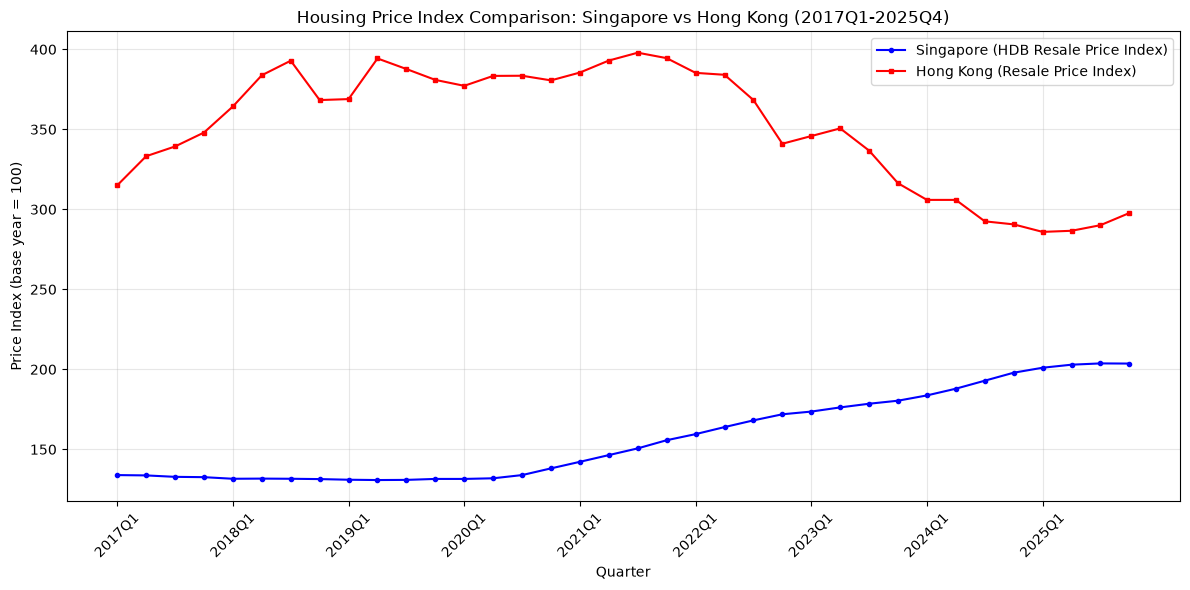

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk_trimmed['quarter_period'] = pd.PeriodIndex(hk_trimmed['quarter'], freq='Q')

fig,ax = plt.subplots(figsize=(12,6))

ax.plot(sg['quarter_period'].astype(str), sg['resale_price_index'], label='Singapore (HDB Resale Price Index)', marker='o', markersize=3, color='blue')
ax.plot(hk_trimmed['quarter_period'].astype(str), hk_trimmed['hk_price_index'], label='Hong Kong (Resale Price Index)', marker='s', markersize=3, color='red')

ax.set_xlabel('Quarter')
ax.set_ylabel('Price Index (base year = 100)')
ax.set_title("Housing Price Index Comparison: Singapore vs Hong Kong (2017Q1-2025Q4)")
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

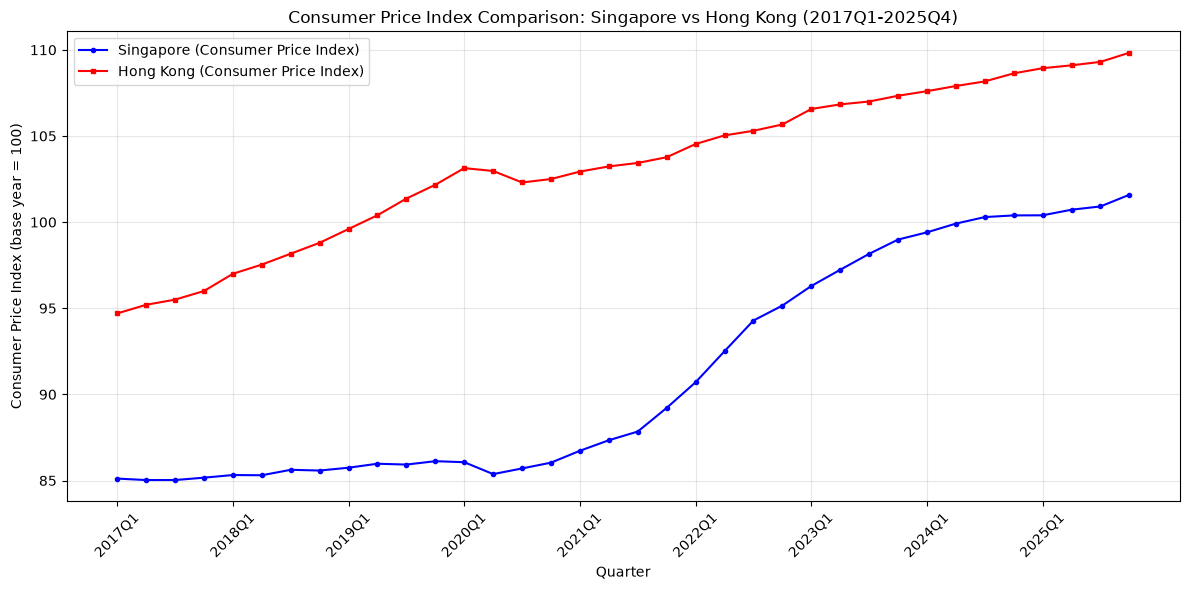

In [16]:
sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk_trimmed['quarter_period'] = pd.PeriodIndex(hk_trimmed['quarter'], freq='Q')

fig,ax = plt.subplots(figsize=(12,6))

ax.plot(sg['quarter_period'].astype(str), sg['cpi'], label='Singapore (Consumer Price Index)', marker='o', markersize=3, color='blue')
ax.plot(hk_trimmed['quarter_period'].astype(str), hk_trimmed['hk_cpi'], label='Hong Kong (Consumer Price Index)', marker='s', markersize=3, color='red')

ax.set_xlabel('Quarter')
ax.set_ylabel('Consumer Price Index (base year = 100)')
ax.set_title("Consumer Price Index Comparison: Singapore vs Hong Kong (2017Q1-2025Q4)")
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

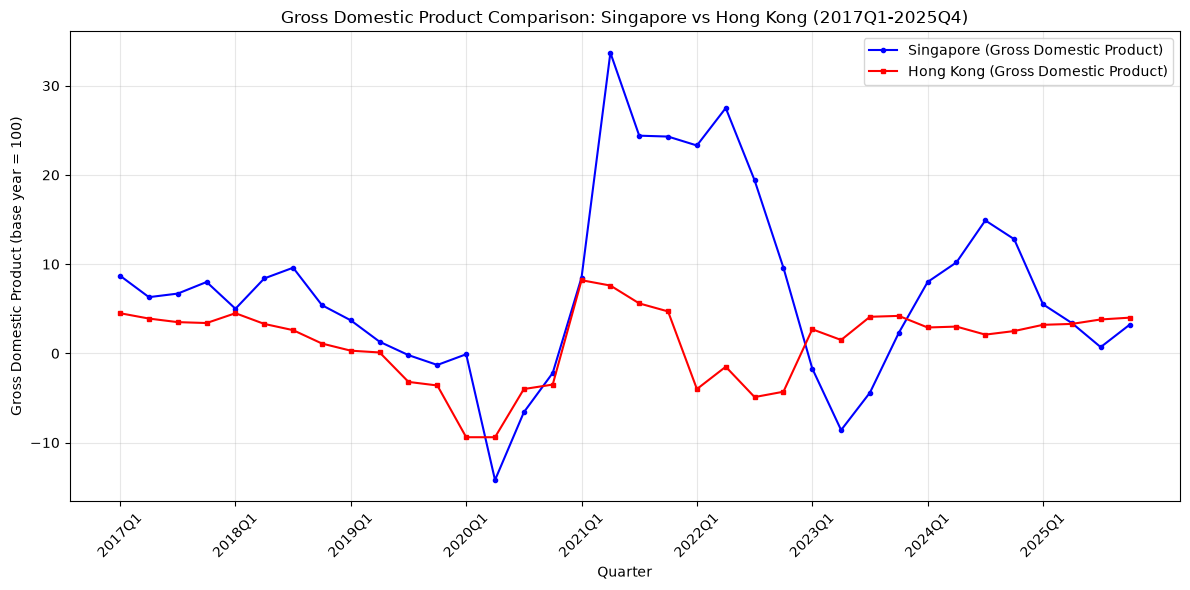

In [17]:
sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk_trimmed['quarter_period'] = pd.PeriodIndex(hk_trimmed['quarter'], freq='Q')

fig,ax = plt.subplots(figsize=(12,6))

ax.plot(sg['quarter_period'].astype(str), sg['gdp'], label='Singapore (Gross Domestic Product)', marker='o', markersize=3, color='blue')
ax.plot(hk_trimmed['quarter_period'].astype(str), hk_trimmed['hk_gdp'], label='Hong Kong (Gross Domestic Product)', marker='s', markersize=3, color='red')

ax.set_xlabel('Quarter')
ax.set_ylabel('Gross Domestic Product (base year = 100)')
ax.set_title("Gross Domestic Product Comparison: Singapore vs Hong Kong (2017Q1-2025Q4)")
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

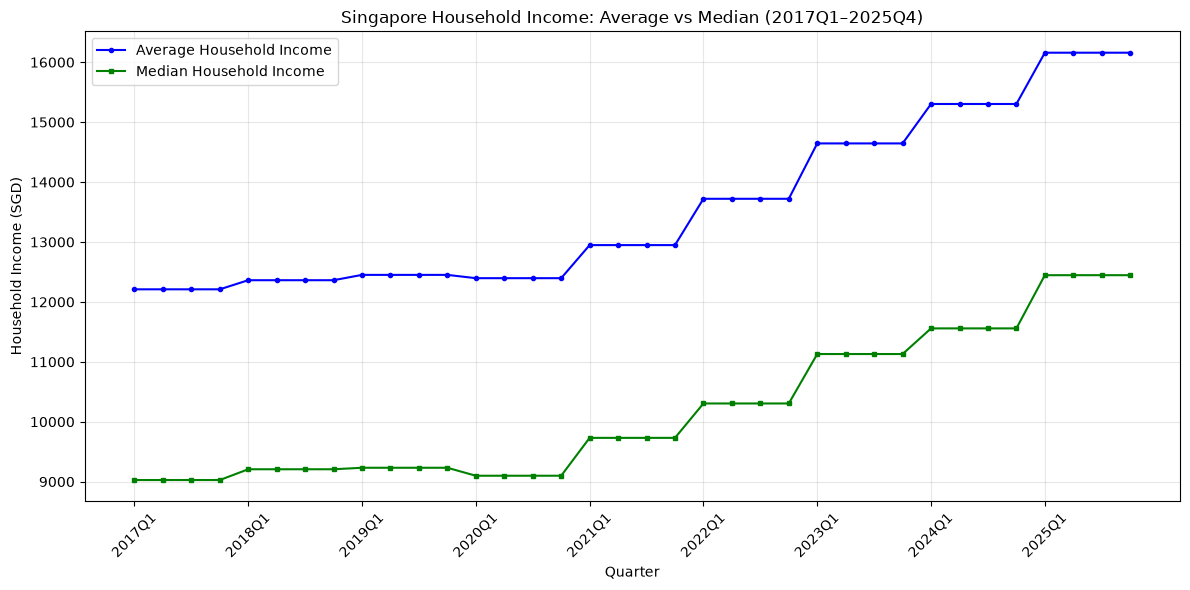

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sg['quarter_period'].astype(str), sg['income_avg'],
        label='Average Household Income', marker='o', markersize=3, color='blue')
ax.plot(sg['quarter_period'].astype(str), sg['income_median'],
        label='Median Household Income', marker='s', markersize=3, color='green')

ax.set_xlabel('Quarter')
ax.set_ylabel('Household Income (SGD)')
ax.set_title('Singapore Household Income: Average vs Median (2017Q1–2025Q4)')
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

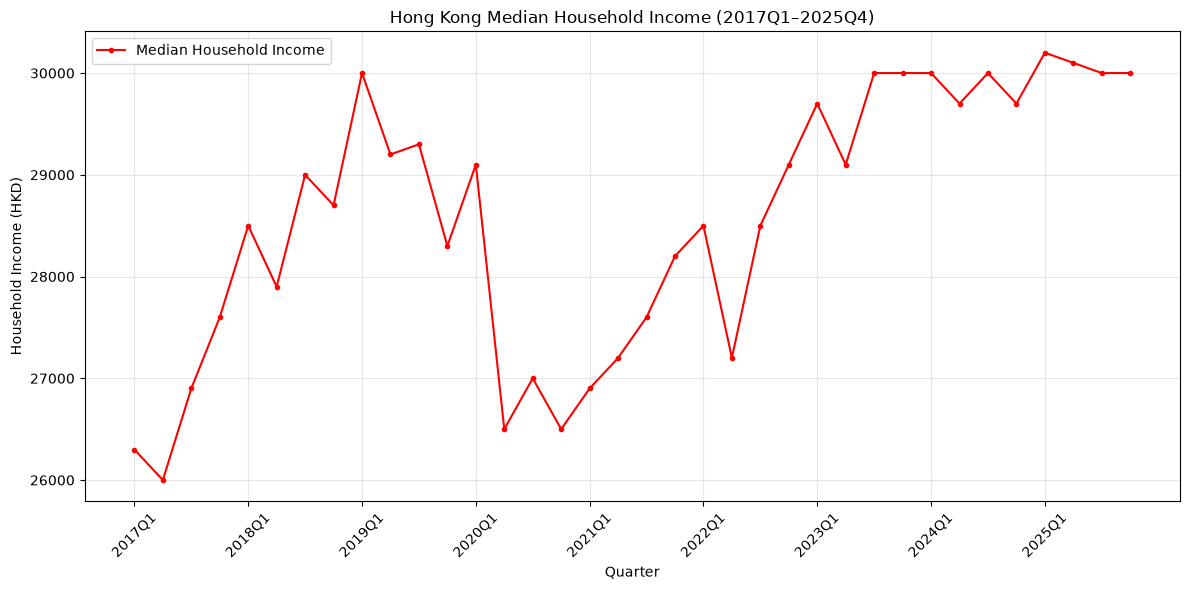

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(hk_trimmed['quarter_period'].astype(str), hk_trimmed['hk_income_median'],
        label='Median Household Income', marker='o', markersize=3, color='red')

ax.set_xlabel('Quarter')
ax.set_ylabel('Household Income (HKD)')
ax.set_title('Hong Kong Median Household Income (2017Q1–2025Q4)')
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

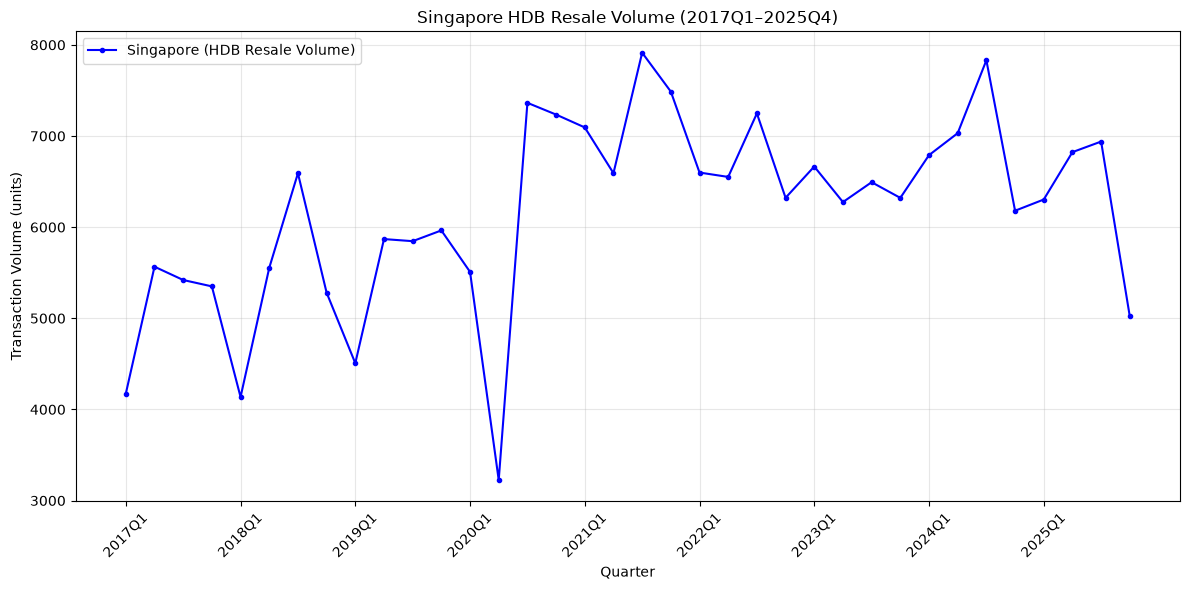

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sg['quarter_period'].astype(str), sg['resale_volume'], label='Singapore (HDB Resale Volume)', marker='o', markersize=3, color='blue')

ax.set_xlabel('Quarter')
ax.set_ylabel('Transaction Volume (units)')
ax.set_title('Singapore HDB Resale Volume (2017Q1–2025Q4)')
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

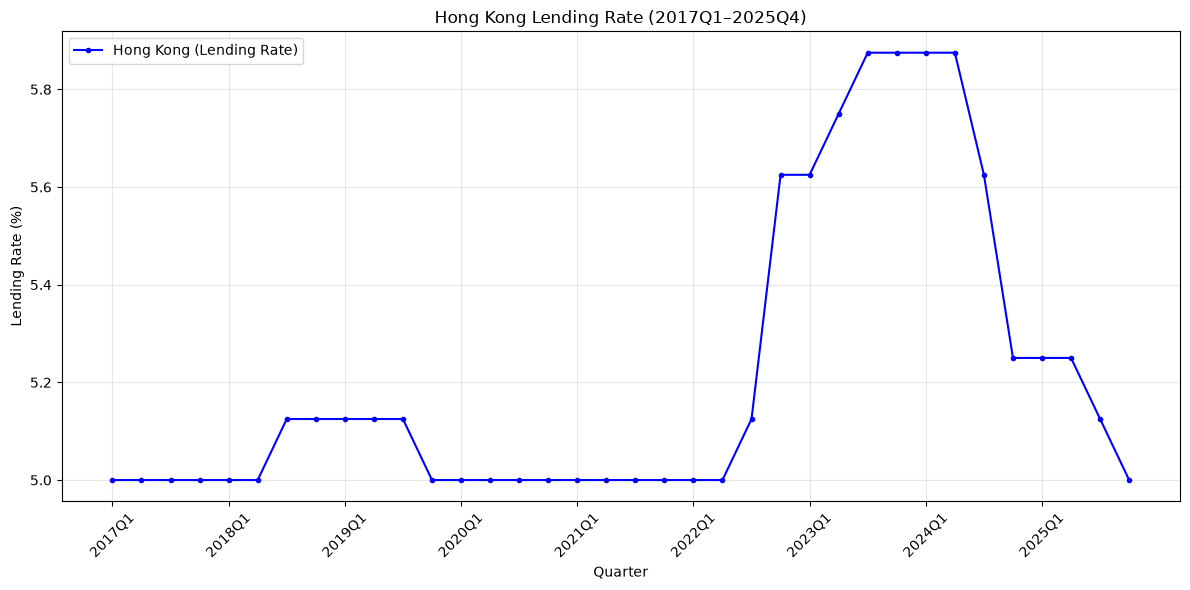

<Figure size 640x480 with 0 Axes>

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(hk_trimmed['quarter_period'].astype(str), hk_trimmed['hk_lending_rate'], label='Hong Kong (Lending Rate)', marker='o', markersize=3, color='blue')

ax.set_xlabel('Quarter')
ax.set_ylabel('Lending Rate (%)')
ax.set_title('Hong Kong Lending Rate (2017Q1–2025Q4)')
ax.legend()

ax.set_xticks(ax.get_xticks()[::4])
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

plt.savefig('Figures/sg_hk_price_index.png', dpi=150, bbox_inches='tight')

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sg = sg.copy()
hk = hk_trimmed.copy()
sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk['quarter_period'] = pd.PeriodIndex(hk['quarter'], freq='Q')

def rebase(s):
    return s / s.iloc[0] * 100   # 2017Q1 = 100

# Re-indexed series (2017Q1 = 100) so levels are comparable across cities
sg['price_idx']  = rebase(sg['resale_price_index'])
sg['cpi_idx']    = rebase(sg['cpi'])
sg['income_idx'] = rebase(sg['income_median'])

hk['price_idx']  = rebase(hk['hk_price_index'])
hk['cpi_idx']    = rebase(hk['hk_cpi'])
hk['income_idx'] = rebase(hk['hk_income_median'])

# Affordability index: price growth relative to income growth (higher = less affordable)
# Within-city ratio, so no FX conversion needed
sg['afford_idx'] = sg['price_idx'] / sg['income_idx'] * 100
hk['afford_idx'] = hk['price_idx'] / hk['income_idx'] * 100

# YoY growth rates (first 4 quarters will be NaN)
for df, p, i in [(sg, 'resale_price_index', 'income_median'), (hk, 'hk_price_index', 'hk_income_median')]:
    df['price_yoy']  = df[p].pct_change(4) * 100
    df['income_yoy'] = df[i].pct_change(4) * 100

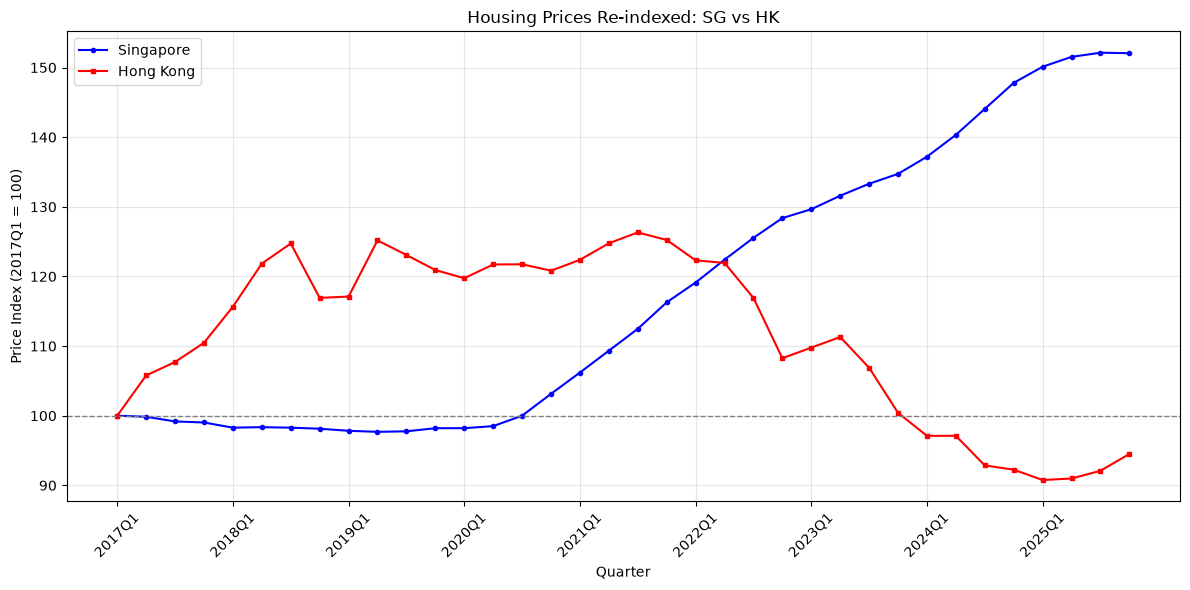

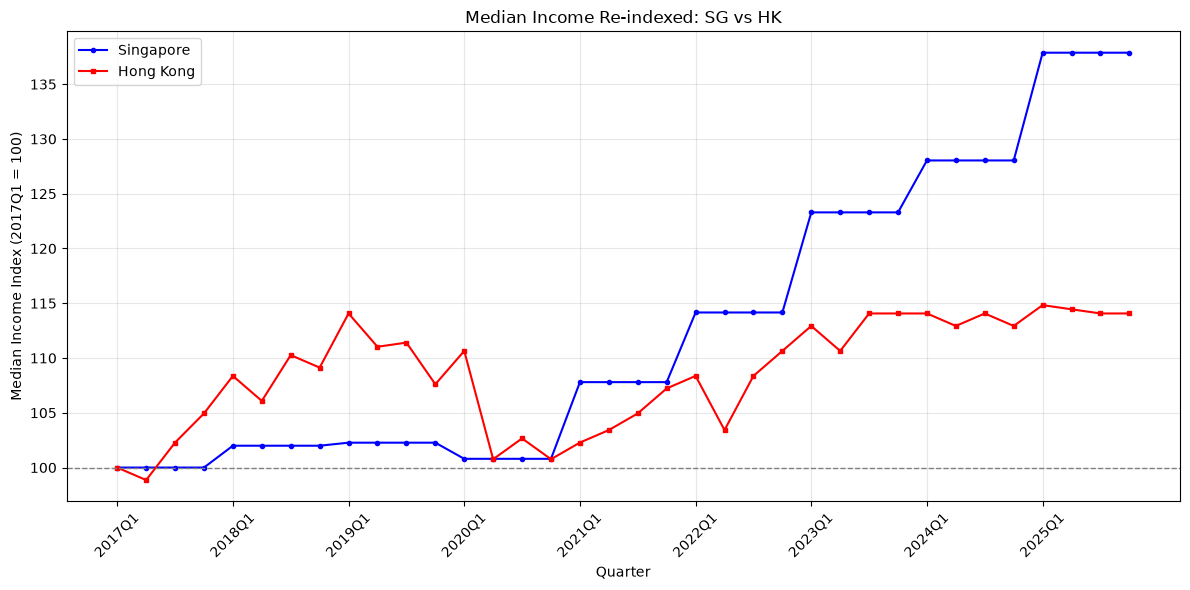

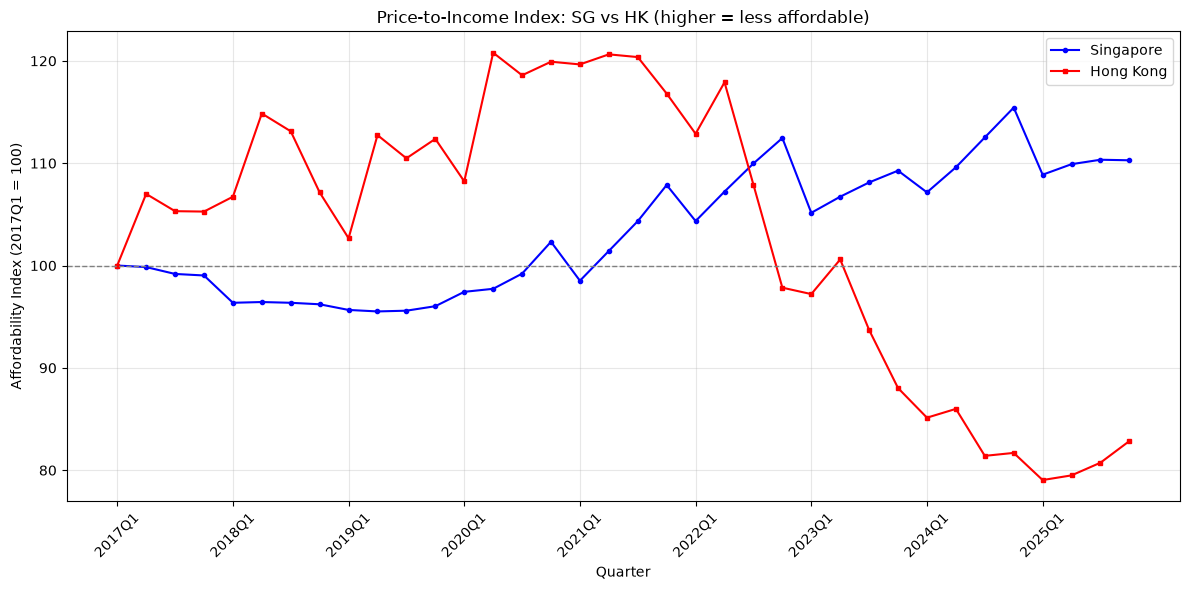

In [23]:
def compare_plot(col, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(sg['quarter_period'].astype(str), sg[col], label='Singapore', marker='o', markersize=3, color='blue')
    ax.plot(hk['quarter_period'].astype(str), hk[col], label='Hong Kong', marker='s', markersize=3, color='red')
    ax.axhline(100, color='gray', linestyle='--', linewidth=1)
    ax.set_xlabel('Quarter'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend()
    ax.set_xticks(ax.get_xticks()[::4])
    plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

import os; os.makedirs('Figures', exist_ok=True)
compare_plot('price_idx',  'Price Index (2017Q1 = 100)',       'Housing Prices Re-indexed: SG vs HK',        'Figures/price_rebased.png')
compare_plot('income_idx', 'Median Income Index (2017Q1 = 100)', 'Median Income Re-indexed: SG vs HK',        'Figures/income_rebased.png')
compare_plot('afford_idx', 'Affordability Index (2017Q1 = 100)', 'Price-to-Income Index: SG vs HK (higher = less affordable)', 'Figures/afford_idx.png')

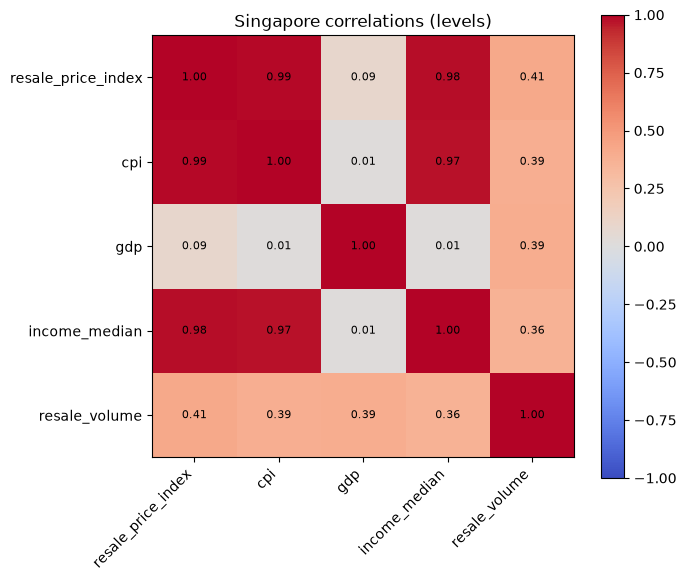

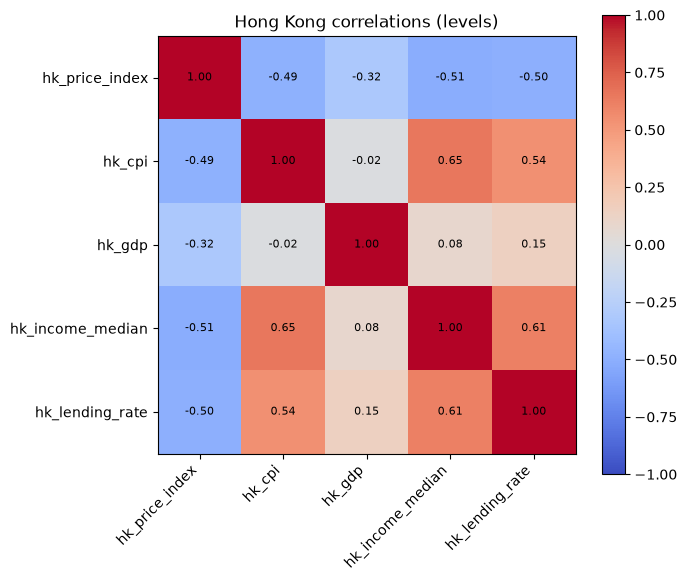

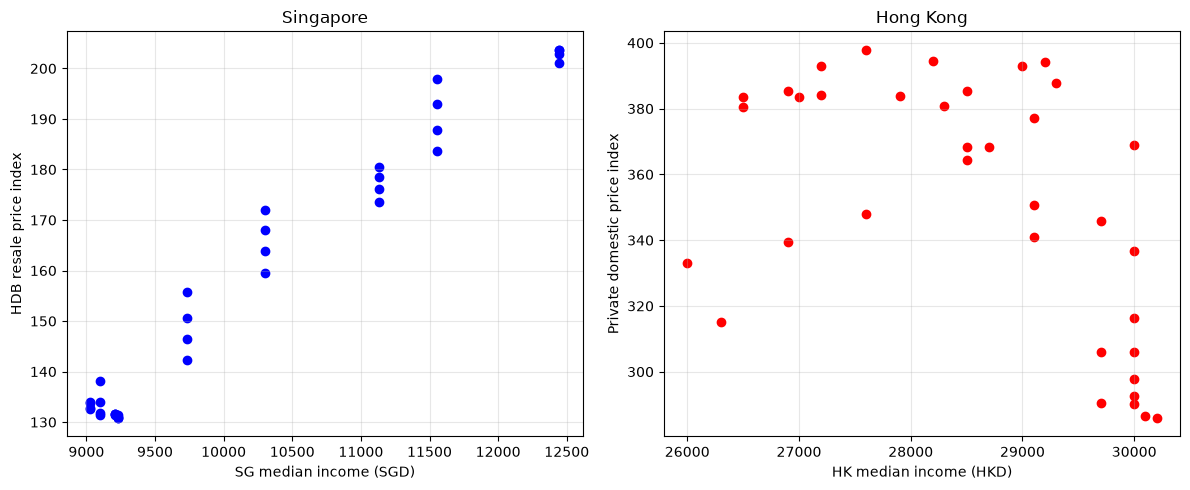

In [24]:
sg_cols = ['resale_price_index', 'cpi', 'gdp', 'income_median', 'resale_volume']
hk_cols = ['hk_price_index', 'hk_cpi', 'hk_gdp', 'hk_income_median', 'hk_lending_rate']

def corr_heatmap(df, cols, title, fname):
    c = df[cols].corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(c, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right')
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f'{c.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
    plt.colorbar(im); ax.set_title(title); plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches='tight'); plt.show()
    return c

sg_corr = corr_heatmap(sg, sg_cols, 'Singapore correlations (levels)', 'Figures/sg_corr.png')
hk_corr = corr_heatmap(hk, hk_cols, 'Hong Kong correlations (levels)', 'Figures/hk_corr.png')

# Price vs income scatter, both cities
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(sg['income_median'], sg['resale_price_index'], color='blue')
axes[0].set_xlabel('SG median income (SGD)'); axes[0].set_ylabel('HDB resale price index'); axes[0].set_title('Singapore')
axes[1].scatter(hk['hk_income_median'], hk['hk_price_index'], color='red')
axes[1].set_xlabel('HK median income (HKD)'); axes[1].set_ylabel('Private domestic price index'); axes[1].set_title('Hong Kong')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('Figures/price_vs_income.png', dpi=150, bbox_inches='tight'); plt.show()

In [25]:
covid_start, covid_end = pd.Period('2020Q1', 'Q'), pd.Period('2022Q2', 'Q')
for df in (sg, hk):
    df['covid'] = df['quarter_period'].between(covid_start, covid_end).astype(int)

# Quick summary table for your write-up
summary = pd.DataFrame({
    'SG price growth 2017Q1-2025Q4 (%)':  [(sg['price_idx'].iloc[-1] - 100)],
    'HK price growth 2017Q1-2025Q4 (%)':  [(hk['price_idx'].iloc[-1] - 100)],
    'SG income growth (%)':               [(sg['income_idx'].iloc[-1] - 100)],
    'HK income growth (%)':               [(hk['income_idx'].iloc[-1] - 100)],
    'SG final affordability idx':         [sg['afford_idx'].iloc[-1]],
    'HK final affordability idx':         [hk['afford_idx'].iloc[-1]],
}).T.round(1)
print(summary)

sg.drop(columns='quarter_period').to_csv('Data/Clean/sg_model_ready.csv', index=False)
hk.drop(columns='quarter_period').to_csv('Data/Clean/hk_model_ready.csv', index=False)

                                       0
SG price growth 2017Q1-2025Q4 (%)   52.1
HK price growth 2017Q1-2025Q4 (%)   -5.5
SG income growth (%)                37.9
HK income growth (%)                14.1
SG final affordability idx         110.3
HK final affordability idx          82.9


In [26]:
%pip install statsmodels


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

def baseline_ols(df, target, features, name, split='2023Q4'):
    d = df.dropna(subset=[target] + features).copy()
    train = d[d['quarter_period'] <= pd.Period(split, 'Q')]
    test  = d[d['quarter_period'] >  pd.Period(split, 'Q')]
    X_tr = sm.add_constant(train[features]); X_te = sm.add_constant(test[features], has_constant='add')
    model = sm.OLS(train[target], X_tr).fit()
    rmse = np.sqrt(mean_squared_error(test[target], model.predict(X_te)))
    print(f'\n=== {name} baseline OLS ===')
    print(model.summary().tables[1])
    print(f'Train R²: {model.rsquared:.3f} | Test RMSE: {rmse:.2f} (n_train={len(train)}, n_test={len(test)})')
    return model, rmse

sg_model, sg_rmse = baseline_ols(sg, 'resale_price_index', ['cpi', 'gdp', 'income_median', 'covid'], 'Singapore')
hk_model, hk_rmse = baseline_ols(hk, 'hk_price_index', ['hk_cpi', 'hk_gdp', 'hk_income_median', 'hk_lending_rate', 'covid'], 'Hong Kong')


=== Singapore baseline OLS ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          -191.4062     14.182    -13.496      0.000    -220.744    -162.068
cpi               3.6554      0.435      8.404      0.000       2.756       4.555
gdp               0.1967      0.040      4.910      0.000       0.114       0.280
income_median     0.0011      0.003      0.402      0.691      -0.005       0.007
covid             3.1838      0.961      3.314      0.003       1.196       5.171
Train R²: 0.987 | Test RMSE: 8.39 (n_train=28, n_test=8)

=== Hong Kong baseline OLS ===
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              224.0623     85.720      2.614      0.016      46.291     401.834
hk_cpi               3.7328      1.726      2.162 

In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

print(os.getcwd())  # should be your project folder, the one containing Data/
os.makedirs('Figures', exist_ok=True)

# --- Load and trim ---
sg = pd.read_csv('Data/Clean/singapore_merged.csv')
hk = pd.read_csv('Data/Clean/hongkong_merged.csv')
hk = hk[(hk['quarter'] >= '2017Q1') & (hk['quarter'] <= '2025Q4')].copy().reset_index(drop=True)
sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk['quarter_period'] = pd.PeriodIndex(hk['quarter'], freq='Q')

# --- Re-index, affordability, YoY ---
def rebase(s): return s / s.iloc[0] * 100
sg['price_idx'], sg['income_idx'] = rebase(sg['resale_price_index']), rebase(sg['income_median'])
hk['price_idx'], hk['income_idx'] = rebase(hk['hk_price_index']), rebase(hk['hk_income_median'])
for df in (sg, hk):
    df['afford_idx'] = df['price_idx'] / df['income_idx'] * 100
for df, p, i, c in [(sg, 'resale_price_index', 'income_median', 'cpi'),
                    (hk, 'hk_price_index', 'hk_income_median', 'hk_cpi')]:
    df['price_yoy']  = df[p].pct_change(4) * 100
    df['income_yoy'] = df[i].pct_change(4) * 100
    df['cpi_yoy']    = df[c].pct_change(4) * 100

# --- COVID dummy ---
for df in (sg, hk):
    df['covid'] = df['quarter_period'].between(pd.Period('2020Q1','Q'), pd.Period('2022Q2','Q')).astype(int)

# --- Functions ---
def baseline_ols(df, target, features, name, split='2023Q4'):
    d = df.dropna(subset=[target] + features).copy()
    train = d[d['quarter_period'] <= pd.Period(split, 'Q')]
    test  = d[d['quarter_period'] >  pd.Period(split, 'Q')]
    X_tr = sm.add_constant(train[features]); X_te = sm.add_constant(test[features], has_constant='add')
    model = sm.OLS(train[target], X_tr).fit()
    rmse = np.sqrt(mean_squared_error(test[target], model.predict(X_te)))
    print(f'\n=== {name} baseline OLS ===')
    print(model.summary().tables[1])
    print(f'Train R²: {model.rsquared:.3f} | Test RMSE: {rmse:.2f} (n_train={len(train)}, n_test={len(test)})')
    return model, rmse

def diagnostics(model, name):
    X, names = model.model.exog, model.model.exog_names
    vif = pd.DataFrame({'feature': names,
                        'VIF': [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
    print(f'\n=== {name} ===')
    print(f'Durbin-Watson: {durbin_watson(model.resid):.2f}  (near 2 = fine, near 0 = strong autocorrelation)')
    print(vif[vif.feature != 'const'].round(1).to_string(index=False))

# --- Fit the levels baseline ---
sg_model, sg_rmse = baseline_ols(sg, 'resale_price_index', ['cpi', 'gdp', 'income_median', 'covid'], 'Singapore')
hk_model, hk_rmse = baseline_ols(hk, 'hk_price_index', ['hk_cpi', 'hk_gdp', 'hk_income_median', 'hk_lending_rate', 'covid'], 'Hong Kong')

# --- Cell 6 diagnostics ---
diagnostics(sg_model, 'Singapore')
diagnostics(hk_model, 'Hong Kong')

/Users/yashvibhansali/Documents/Housing Affordability Project/Housing Affordability

=== Singapore baseline OLS ===
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          -191.4062     14.182    -13.496      0.000    -220.744    -162.068
cpi               3.6554      0.435      8.404      0.000       2.756       4.555
gdp               0.1967      0.040      4.910      0.000       0.114       0.280
income_median     0.0011      0.003      0.402      0.691      -0.005       0.007
covid             3.1838      0.961      3.314      0.003       1.196       5.171
Train R²: 0.987 | Test RMSE: 8.39 (n_train=28, n_test=8)

=== Hong Kong baseline OLS ===
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              224.0623     85.720      2.614  

In [29]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

def diagnostics(model, name):
    X = model.model.exog
    names = model.model.exog_names
    vif = pd.DataFrame({'feature': names,
                        'VIF': [variance_inflation_factor(X, i) for i in range(X.shape[1])]})
    print(f'\n=== {name} ===')
    print(f'Durbin-Watson: {durbin_watson(model.resid):.2f}  (near 2 = fine, near 0 = strong autocorrelation)')
    print(vif[vif.feature != 'const'].round(1).to_string(index=False))

diagnostics(sg_model, 'Singapore')
diagnostics(hk_model, 'Hong Kong')


=== Singapore ===
Durbin-Watson: 1.06  (near 2 = fine, near 0 = strong autocorrelation)
      feature  VIF
          cpi 22.4
          gdp  1.2
income_median 22.1
        covid  1.2

=== Hong Kong ===
Durbin-Watson: 1.46  (near 2 = fine, near 0 = strong autocorrelation)
         feature  VIF
          hk_cpi  6.0
          hk_gdp  1.3
hk_income_median  2.4
 hk_lending_rate  5.2
           covid  4.5


In [30]:
sg['cpi_yoy'] = sg['cpi'].pct_change(4) * 100
hk['cpi_yoy'] = hk['hk_cpi'].pct_change(4) * 100

sg_feats_yoy = ['cpi_yoy', 'gdp', 'income_yoy', 'covid']
hk_feats_yoy = ['cpi_yoy', 'hk_gdp', 'income_yoy', 'hk_lending_rate', 'covid']

sg_model_yoy, sg_rmse_yoy = baseline_ols(sg, 'price_yoy', sg_feats_yoy, 'Singapore (YoY)')
hk_model_yoy, hk_rmse_yoy = baseline_ols(hk, 'price_yoy', hk_feats_yoy, 'Hong Kong (YoY)')
diagnostics(sg_model_yoy, 'Singapore (YoY)')
diagnostics(hk_model_yoy, 'Hong Kong (YoY)')


=== Singapore (YoY) baseline OLS ===
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0409      0.508     -4.014      0.001      -3.105      -0.977
cpi_yoy        1.2355      0.192      6.440      0.000       0.834       1.637
gdp            0.0450      0.029      1.529      0.143      -0.017       0.107
income_yoy     0.4358      0.138      3.169      0.005       0.148       0.724
covid          5.3755      0.654      8.218      0.000       4.006       6.745
Train R²: 0.945 | Test RMSE: 4.82 (n_train=24, n_test=8)

=== Hong Kong (YoY) baseline OLS ===
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              98.4745     22.277      4.421      0.000      51.673     145.276
cpi_yoy             3.2476      1.534      2.117      0.048   


=== Singapore (n_train=24, n_test=8) ===
             Model  Test RMSE
Naive (train mean)       2.92
               OLS       4.82
     Random Forest       4.48
 Gradient Boosting       6.28


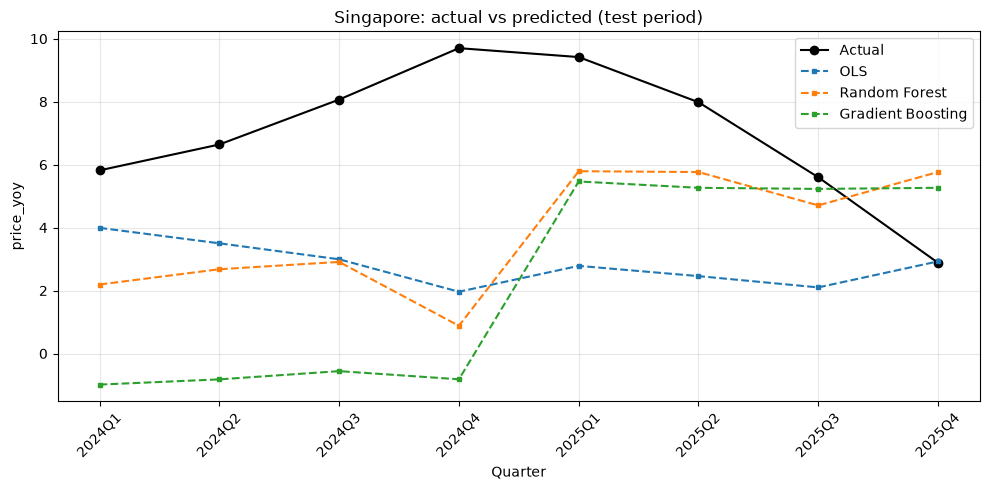


=== Hong Kong (n_train=24, n_test=8) ===
             Model  Test RMSE
Naive (train mean)       9.19
               OLS       4.55
     Random Forest       6.28
 Gradient Boosting       5.98


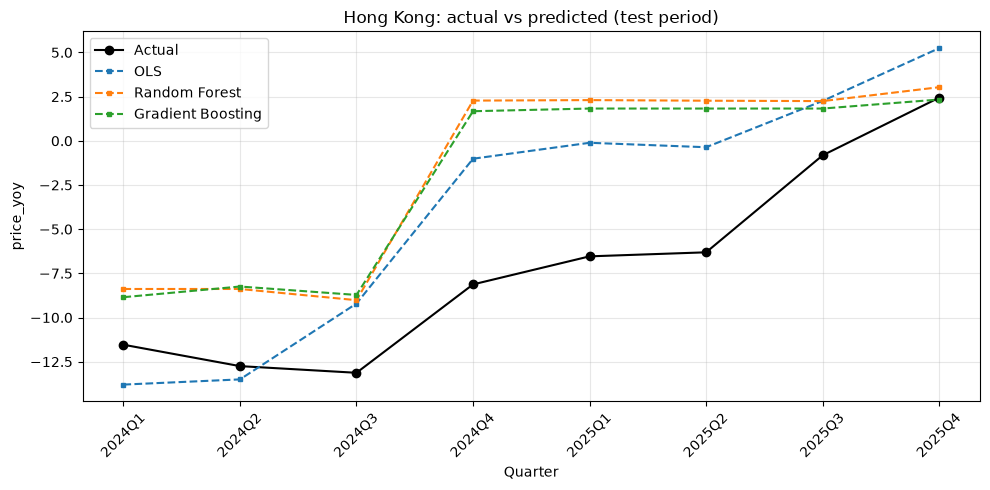

In [31]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

def compare_models(df, target, features, name, split='2023Q4'):
    d = df.dropna(subset=[target] + features).copy()
    train = d[d['quarter_period'] <= pd.Period(split, 'Q')]
    test  = d[d['quarter_period'] >  pd.Period(split, 'Q')]
    models = {
        'OLS': LinearRegression(),
        'Random Forest': RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42),
        'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                       max_depth=2, random_state=42),
    }
    rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))
    rows = [('Naive (train mean)', rmse(test[target], np.full(len(test), train[target].mean())))]
    preds = {}
    for label, m in models.items():
        m.fit(train[features], train[target])
        preds[label] = m.predict(test[features])
        rows.append((label, rmse(test[target], preds[label])))
    res = pd.DataFrame(rows, columns=['Model', 'Test RMSE']).round(2)
    print(f'\n=== {name} (n_train={len(train)}, n_test={len(test)}) ===')
    print(res.to_string(index=False))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(test['quarter_period'].astype(str), test[target].values, 'k-o', label='Actual')
    for label, p in preds.items():
        ax.plot(test['quarter_period'].astype(str), p, '--', marker='s', markersize=3, label=label)
    ax.set_title(f'{name}: actual vs predicted (test period)')
    ax.set_xlabel('Quarter'); ax.set_ylabel(target); ax.legend(); ax.grid(alpha=0.3)
    plt.xticks(rotation=45); plt.tight_layout()
    plt.savefig(f'Figures/{name.split()[0].lower()}_model_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    return models['Random Forest'], res

sg_rf, sg_res = compare_models(sg, 'price_yoy', sg_feats_yoy, 'Singapore')
hk_rf, hk_res = compare_models(hk, 'price_yoy', hk_feats_yoy, 'Hong Kong')

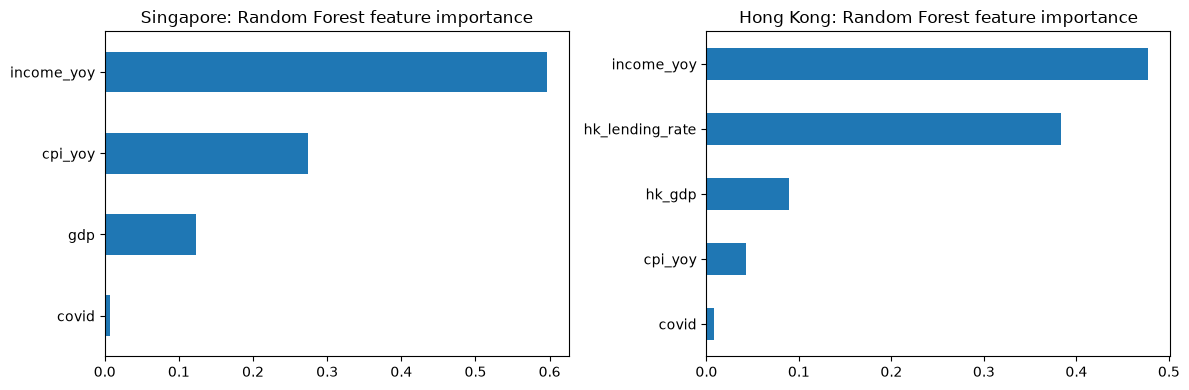

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rf, feats, title in [(axes[0], sg_rf, sg_feats_yoy, 'Singapore'),
                             (axes[1], hk_rf, hk_feats_yoy, 'Hong Kong')]:
    imp = pd.Series(rf.feature_importances_, index=feats).sort_values()
    imp.plot.barh(ax=ax); ax.set_title(f'{title}: Random Forest feature importance')
plt.tight_layout()
plt.savefig('Figures/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [33]:
from sklearn.model_selection import TimeSeriesSplit

def cv_rmse(df, target, features, n_splits=5):
    d = df.dropna(subset=[target] + features)
    X, y = d[features].values, d[target].values
    out = {'OLS': [], 'Random Forest': []}
    for tr, te in TimeSeriesSplit(n_splits=n_splits).split(X):
        for label, m in [('OLS', LinearRegression()),
                         ('Random Forest', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42))]:
            m.fit(X[tr], y[tr])
            out[label].append(np.sqrt(mean_squared_error(y[te], m.predict(X[te]))))
    return {k: round(float(np.mean(v)), 2) for k, v in out.items()}

print('SG CV RMSE:', cv_rmse(sg, 'price_yoy', sg_feats_yoy))
print('HK CV RMSE:', cv_rmse(hk, 'price_yoy', hk_feats_yoy))

SG CV RMSE: {'OLS': 6.36, 'Random Forest': 4.5}
HK CV RMSE: {'OLS': 18.68, 'Random Forest': 7.19}


In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit

print(os.getcwd())  # must be the folder that contains Data/

# --- Load and trim ---
sg = pd.read_csv('Data/Clean/singapore_merged.csv')
hk = pd.read_csv('Data/Clean/hongkong_merged.csv')
hk = hk[(hk['quarter'] >= '2017Q1') & (hk['quarter'] <= '2025Q4')].copy().reset_index(drop=True)
sg['quarter_period'] = pd.PeriodIndex(sg['quarter'], freq='Q')
hk['quarter_period'] = pd.PeriodIndex(hk['quarter'], freq='Q')

# --- YoY growth rates ---
for df, p, i, c in [(sg, 'resale_price_index', 'income_median', 'cpi'),
                    (hk, 'hk_price_index', 'hk_income_median', 'hk_cpi')]:
    df['price_yoy']  = df[p].pct_change(4) * 100
    df['income_yoy'] = df[i].pct_change(4) * 100
    df['cpi_yoy']    = df[c].pct_change(4) * 100

# --- COVID dummy ---
for df in (sg, hk):
    df['covid'] = df['quarter_period'].between(pd.Period('2020Q1', 'Q'), pd.Period('2022Q2', 'Q')).astype(int)

# --- Feature lists ---
sg_feats_yoy = ['cpi_yoy', 'gdp', 'income_yoy', 'covid']
hk_feats_yoy = ['cpi_yoy', 'hk_gdp', 'income_yoy', 'hk_lending_rate', 'covid']

# --- Per-fold CV check ---
def cv_detail(df, target, features, name, n_splits=5):
    d = df.dropna(subset=[target] + features)
    X, y = d[features].values, d[target].values
    rows = []
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(X), 1):
        rmse = lambda p: np.sqrt(mean_squared_error(y[te], p))
        r = {'fold': k, 'n_train': len(tr), 'n_test': len(te),
             'Naive': rmse(np.full(len(te), y[tr].mean()))}
        for label, m in [('OLS', LinearRegression()),
                         ('Ridge', Ridge(alpha=10)),
                         ('RF', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42))]:
            m.fit(X[tr], y[tr]); r[label] = rmse(m.predict(X[te]))
        rows.append(r)
    res = pd.DataFrame(rows).round(2)
    print(f'\n=== {name} ===')
    print(res.to_string(index=False))
    print('Mean:', res[['Naive', 'OLS', 'Ridge', 'RF']].mean().round(2).to_dict())
    print('Mean excl. fold 1:', res[res.fold > 1][['Naive', 'OLS', 'Ridge', 'RF']].mean().round(2).to_dict())

cv_detail(sg, 'price_yoy', sg_feats_yoy, 'Singapore')
cv_detail(hk, 'price_yoy', hk_feats_yoy, 'Hong Kong')

/Users/yashvibhansali/Documents/Housing Affordability Project/Housing Affordability

=== Singapore ===
 fold  n_train  n_test  Naive   OLS  Ridge    RF
    1        7       5   3.24  2.91   2.74  3.28
    2       12       5  11.27 19.59  15.70 11.94
    3       17       5   6.84  1.56   1.06  0.76
    4       22       5   1.73  2.89   2.01  3.62
    5       27       5   3.20  4.84   3.58  2.90
Mean: {'Naive': 5.26, 'OLS': 6.36, 'Ridge': 5.02, 'RF': 4.5}
Mean excl. fold 1: {'Naive': 5.76, 'OLS': 7.22, 'Ridge': 5.59, 'RF': 4.8}

=== Hong Kong ===
 fold  n_train  n_test  Naive   OLS  Ridge    RF
    1        7       5   7.85 53.18  14.60  5.42
    2       12       5   2.70 19.70   6.82  5.51
    3       17       5  13.04 10.58  13.70 13.40
    4       22       5  12.09  4.89  11.31  4.12
    5       27       5   4.94  5.06   3.98  7.53
Mean: {'Naive': 8.12, 'OLS': 18.68, 'Ridge': 10.08, 'RF': 7.2}
Mean excl. fold 1: {'Naive': 8.19, 'OLS': 10.06, 'Ridge': 8.95, 'RF': 7.64}


In [37]:
def cv_detail2(df, target, features, name):
    d = df.dropna(subset=[target] + features)
    X, y = d[features].values, d[target].values
    rows = []
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4, test_size=4).split(X), 1):
        rmse = lambda p: np.sqrt(mean_squared_error(y[te], p))
        r = {'fold': k, 'n_train': len(tr), 'Naive': rmse(np.full(len(te), y[tr].mean()))}
        for label, m in [('OLS', LinearRegression()), ('Ridge', Ridge(alpha=10)),
                         ('RF', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42))]:
            m.fit(X[tr], y[tr]); r[label] = rmse(m.predict(X[te]))
        rows.append(r)
    res = pd.DataFrame(rows).round(2)
    print(f'\n=== {name} (4 folds, min train = 16) ===')
    print(res.to_string(index=False))
    print('Mean:', res[['Naive', 'OLS', 'Ridge', 'RF']].mean().round(2).to_dict())

cv_detail2(sg, 'price_yoy', sg_feats_yoy, 'Singapore')
cv_detail2(hk, 'price_yoy', hk_feats_yoy, 'Hong Kong')


=== Singapore (4 folds, min train = 16) ===
 fold  n_train  Naive  OLS  Ridge   RF
    1       16   8.67 3.30   1.15 1.26
    2       20   2.68 2.78   2.58 2.51
    3       24   2.96 4.97   3.17 5.40
    4       28   2.72 3.56   2.83 2.94
Mean: {'Naive': 4.26, 'OLS': 3.65, 'Ridge': 2.43, 'RF': 3.03}

=== Hong Kong (4 folds, min train = 16) ===
 fold  n_train  Naive  OLS  Ridge    RF
    1       16  11.40 7.59  11.63  8.87
    2       20  11.03 6.18  13.30 14.26
    3       24  12.00 4.23   9.56  6.22
    4       28   4.11 3.40   3.42  1.83
Mean: {'Naive': 9.64, 'OLS': 5.35, 'Ridge': 9.48, 'RF': 7.8}


In [38]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

def cv_scaled(df, target, features, name):
    d = df.dropna(subset=[target] + features)
    X, y = d[features].values, d[target].values
    rows = []
    for k, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4, test_size=4).split(X), 1):
        rmse = lambda p: np.sqrt(mean_squared_error(y[te], p))
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
        m.fit(X[tr], y[tr])
        rows.append({'fold': k, 'Naive': rmse(np.full(len(te), y[tr].mean())),
                     'Ridge_scaled': rmse(m.predict(X[te]))})
    res = pd.DataFrame(rows).round(2)
    print(f'\n=== {name} ===')
    print(res.to_string(index=False))
    print('Mean:', res[['Naive', 'Ridge_scaled']].mean().round(2).to_dict())
    full = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(X, y)
    print('Standardized coefficients (full sample):')
    print(pd.Series(full[-1].coef_, index=features).round(2).sort_values().to_string())

cv_scaled(sg, 'price_yoy', sg_feats_yoy, 'Singapore')
cv_scaled(hk, 'price_yoy', hk_feats_yoy, 'Hong Kong')


=== Singapore ===
 fold  Naive  Ridge_scaled
    1   8.67          2.07
    2   2.68          2.05
    3   2.96          4.84
    4   2.72          3.33
Mean: {'Naive': 4.26, 'Ridge_scaled': 3.07}
Standardized coefficients (full sample):
gdp           1.03
covid         1.52
cpi_yoy       1.60
income_yoy    2.11

=== Hong Kong ===
 fold  Naive  Ridge_scaled
    1  11.40          6.48
    2  11.03          5.02
    3  12.00          4.31
    4   4.11          3.34
Mean: {'Naive': 9.64, 'Ridge_scaled': 4.79}
Standardized coefficients (full sample):
hk_lending_rate   -5.26
income_yoy         1.16
covid              1.19
hk_gdp             3.52
cpi_yoy            3.56


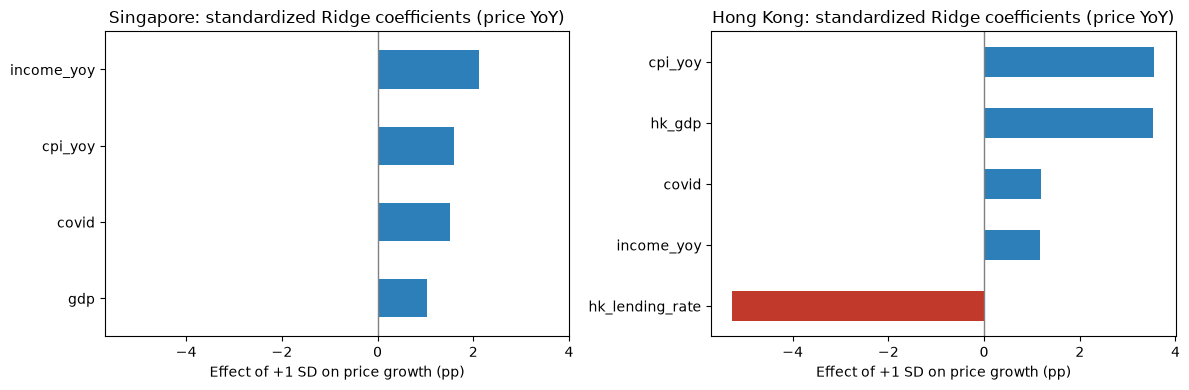

In [40]:
results = pd.DataFrame({
    'City': ['Singapore', 'Hong Kong'],
    'Naive': [4.26, 9.64], 'OLS': [3.65, 5.35],
    'Ridge (scaled)': [3.07, 4.79], 'Random Forest': [3.03, 7.80],
})
results.to_csv('Data/Clean/model_comparison_results.csv', index=False)

# Coefficient chart for the write-up
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sg_coef = pd.Series({'gdp': 1.03, 'covid': 1.52, 'cpi_yoy': 1.60, 'income_yoy': 2.11})
hk_coef = pd.Series({'hk_lending_rate': -5.26, 'income_yoy': 1.16, 'covid': 1.19, 'hk_gdp': 3.52, 'cpi_yoy': 3.56})
for ax, c, t in [(axes[0], sg_coef, 'Singapore'), (axes[1], hk_coef, 'Hong Kong')]:
    c.sort_values().plot.barh(ax=ax, color=['#c0392b' if v < 0 else '#2c7fb8' for v in c.sort_values()])
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(f'{t}: standardized Ridge coefficients (price YoY)')
    ax.set_xlabel('Effect of +1 SD on price growth (pp)')
plt.tight_layout()
plt.savefig('Figures/ridge_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()